In [1]:
import pandas as pd
import numpy as np

# World Happiness Report 2023 — representative data
# Source: https://www.kaggle.com/datasets/ajaypalsinghlo/world-happiness-report-2023

df = pd.read_csv('../data/world_happiness_2023.csv')
df.columns = ['Country','Region','Happiness_Score','GDP','Social_Support',
              'Life_Expectancy','Freedom','Generosity','Corruption']


print(f"Dataset: {len(df)} countries, {len(df.columns)} columns")
print(df.head())

Dataset: 63 countries, 9 columns
       Country                        Region  Happiness_Score     GDP  \
0      Finland                Western Europe            7.804  10.775   
1      Denmark                Western Europe            7.586  10.933   
2      Iceland                Western Europe            7.525  10.878   
3       Israel  Middle East and North Africa            7.473  10.527   
4  Netherlands                Western Europe            7.464  11.015   

   Social_Support  Life_Expectancy  Freedom  Generosity  Corruption  
0           0.954             71.9    0.949       0.142       0.179  
1           0.954             72.7    0.931       0.168       0.234  
2           0.983             72.5    0.961       0.260       0.150  
3           0.916             72.4    0.903       0.149       0.826  
4           0.939             72.4    0.879       0.240       0.296  


In [2]:
import plotly.express as px
import plotly.graph_objects as go

# Explore the dataset before you start
print("Regions in dataset:")
print(df['Region'].value_counts())
print("\nScore range:", df['Happiness_Score'].min(), "–", df['Happiness_Score'].max())
print("\nBottom 10 countries:")
print(df.nsmallest(10, 'Happiness_Score')[['Country','Region','Happiness_Score']])

Regions in dataset:
Region
Western Europe                  15
Latin America and Caribbean     13
Central and Eastern Europe       7
Sub-Saharan Africa               7
Middle East and North Africa     6
North America and ANZ            4
Southeast Asia                   4
South Asia                       4
East Asia                        3
Name: count, dtype: int64

Score range: 1.859 – 7.804

Bottom 10 countries:
        Country                        Region  Happiness_Score
60  Afghanistan                    South Asia            1.859
61      Lebanon  Middle East and North Africa            2.392
62     Zimbabwe            Sub-Saharan Africa            2.995
52     Ethiopia            Sub-Saharan Africa            3.564
53     Tanzania            Sub-Saharan Africa            3.698
48   Bangladesh                    South Asia            3.892
47        India                    South Asia            4.036
50        Kenya            Sub-Saharan Africa            4.112
54       Uganda

In [3]:
# Task 1: Regional comparison bar chart
# -------------------------------------

# Step 1: Compute average happiness score by region
region_avg = (df.groupby('Region')['Happiness_Score']
              .mean()
              .reset_index()
              .sort_values('Happiness_Score'))  # sort for horizontal bar

print(region_avg)

# Step 2: Build your chart
# YOUR CODE HERE


                         Region  Happiness_Score
5                    South Asia         3.618250
7            Sub-Saharan Africa         4.064714
3  Middle East and North Africa         4.943333
6                Southeast Asia         5.695250
2   Latin America and Caribbean         5.699000
1                     East Asia         5.966000
0    Central and Eastern Europe         6.338143
4         North America and ANZ         7.018250
8                Western Europe         7.085533


                         Region  Happiness_Score
5                    South Asia         3.618250
7            Sub-Saharan Africa         4.064714
3  Middle East and North Africa         4.943333
6                Southeast Asia         5.695250
2   Latin America and Caribbean         5.699000
1                     East Asia         5.966000
0    Central and Eastern Europe         6.338143
4         North America and ANZ         7.018250
8                Western Europe         7.085533


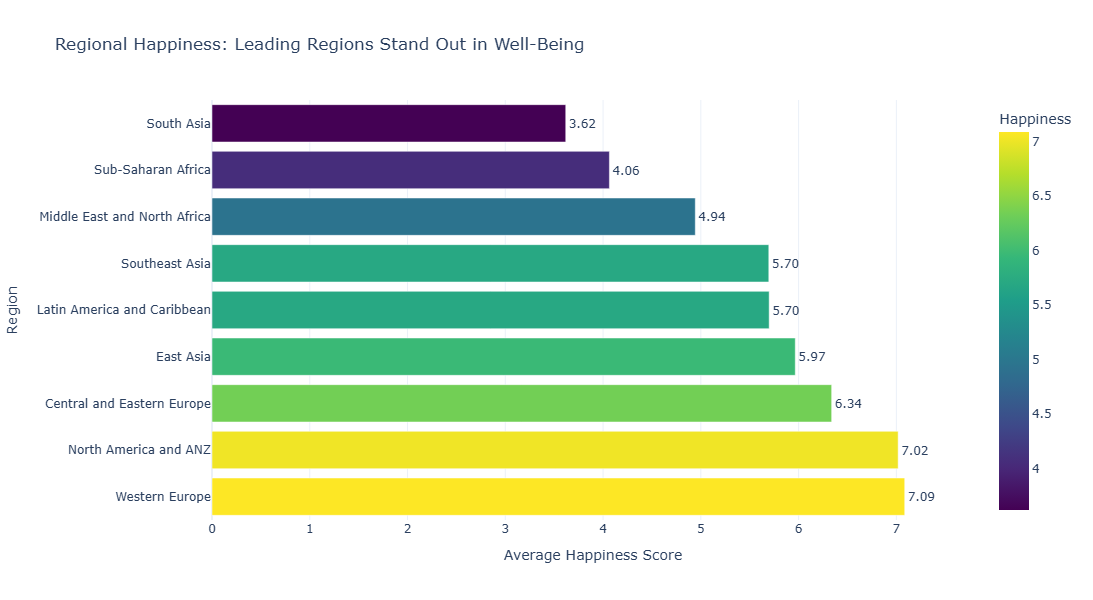

In [4]:
# Step 1: Compute average happiness score by region

region_avg = (
    df.groupby('Region')['Happiness_Score']
      .mean()
      .reset_index()
      .sort_values('Happiness_Score', ascending=True)
)

print(region_avg)


# Step 2: Build the horizontal bar chart

fig = px.bar(
    region_avg,
    x='Happiness_Score',
    y='Region',
    orientation='h',
    text='Happiness_Score',
    color='Happiness_Score',
    color_continuous_scale='Viridis',
    title='Regional Happiness: Leading Regions Stand Out in Well-Being'
)

# Put highest score at the top
fig.update_yaxes(autorange='reversed')

# Zero baseline on x-axis
fig.update_xaxes(
    range=[0, region_avg['Happiness_Score'].max() * 1.1],
    title='Average Happiness Score'
)

# Show values on bars
fig.update_traces(
    texttemplate='%{text:.2f}',
    textposition='outside'
)

# Improve layout
fig.update_layout(
    yaxis_title='Region',
    height=600,
    template='plotly_white',
    coloraxis_colorbar_title='Happiness'
)

fig.show()

In [6]:
top8 = df.nlargest(8, 'Happiness_Score').copy()
top8['Group'] = 'Top 8'

bottom8 = df.nsmallest(8, 'Happiness_Score').copy()
bottom8['Group'] = 'Bottom 8'

combined = pd.concat([bottom8, top8]).sort_values('Happiness_Score')

global_avg = df['Happiness_Score'].mean()

print(f"Global average: {global_avg:.2f}")

Global average: 5.81


In [7]:
import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go

df = pd.read_csv('../data/world_happiness_2023.csv')

df.columns = [
    'Country',
    'Region',
    'Happiness_Score',
    'GDP',
    'Social_Support',
    'Life_Expectancy',
    'Freedom',
    'Generosity',
    'Corruption'
]

In [8]:
top8 = df.nlargest(8, 'Happiness_Score').copy()
top8['Group'] = 'Top 8'

bottom8 = df.nsmallest(8, 'Happiness_Score').copy()
bottom8['Group'] = 'Bottom 8'

combined = pd.concat([bottom8, top8]).sort_values('Happiness_Score')

global_avg = df['Happiness_Score'].mean()

print(f"Global average: {global_avg:.2f}")

Global average: 5.81


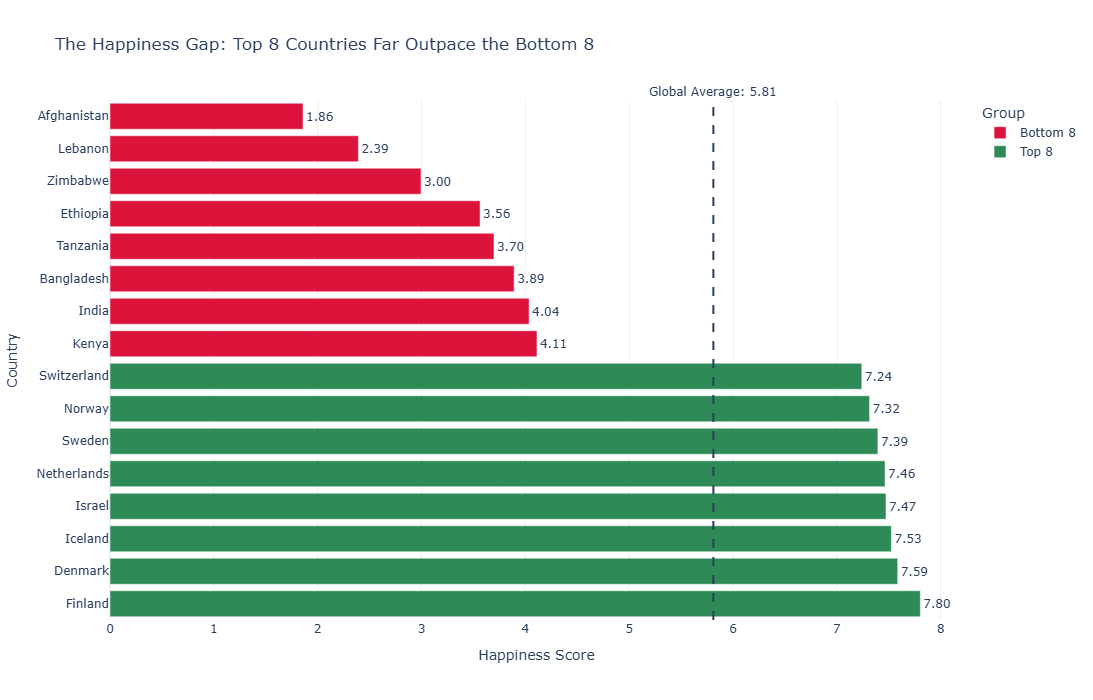

In [9]:
# Step 2: Build the chart

fig = px.bar(
    combined,
    x='Happiness_Score',
    y='Country',
    orientation='h',
    color='Group',
    color_discrete_map={
        'Top 8': 'seagreen',
        'Bottom 8': 'crimson'
    },
    text='Happiness_Score',
    title='The Happiness Gap: Top 8 Countries Far Outpace the Bottom 8'
)

# Show highest happiness at the top
fig.update_yaxes(autorange='reversed')

# Show values on bars
fig.update_traces(
    texttemplate='%{text:.2f}',
    textposition='outside'
)

# Add global average reference line
fig.add_vline(
    x=global_avg,
    line_dash='dash',
    line_width=2,
    annotation_text=f'Global Average: {global_avg:.2f}',
    annotation_position='top'
)

# Improve layout
fig.update_layout(
    xaxis_title='Happiness Score',
    yaxis_title='Country',
    height=700,
    template='plotly_white'
)

fig.show()

In [10]:
# 1. Make sure you are in your repo folder
%cd data_Visualization_yash_32234390

# 2. Pull the newest class material from the professor
!git pull upstream main

# 3. Add your specific exercise folder
!git add Week02_ex/

# 4. Commit your work
!git commit -m "Lecture 02 exercise"

# 5. Push everything to your GitHub
!git push origin main

[WinError 2] The system cannot find the file specified: 'data_Visualization_yash_32234390'
C:\Users\LENOVO\data_visualization_yash_32234390\data_visualization_yash_32234390\week02
Already up to date.


From https://github.com/dina-deifallah/data-viz-class-material-w2026
 * branch            main       -> FETCH_HEAD
fatal: pathspec 'Week02_ex/' did not match any files


On branch main
Your branch is up to date with 'origin/main'.

Changes not staged for commit:
  (use "git add <file>..." to update what will be committed)
  (use "git restore <file>..." to discard changes in working directory)
	modified:   lecture02_exercise.ipynb

Untracked files:
  (use "git add <file>..." to include in what will be committed)
	../data_visualization_yash_32234390/
	Untitled.ipynb
	Untitled1.ipynb
	iframe_figures/

no changes added to commit (use "git add" and/or "git commit -a")


Everything up-to-date


In [11]:
# 1. Make sure you are in your repo folder
%cd C:\Users\LENOVO\data_visualization_yash_32234390

# 2. Pull the newest class material from the professor
!git pull upstream main

# 3. Add your specific exercise folder
!git add week02/

# 4. Commit your work
!git commit -m "Lecture 02 exercise"

# 5. Push everything to your GitHub
!git push origin main

C:\Users\LENOVO\data_visualization_yash_32234390


fatal: not a git repository (or any of the parent directories): .git
fatal: not a git repository (or any of the parent directories): .git
fatal: not a git repository (or any of the parent directories): .git
fatal: not a git repository (or any of the parent directories): .git


In [12]:
%cd C:\Users\LENOVO\data_visualization_yash_32234390\data_visualization_yash_32234390

C:\Users\LENOVO\data_visualization_yash_32234390\data_visualization_yash_32234390


In [13]:
!git status

On branch main
Your branch is up to date with 'origin/main'.

Changes not staged for commit:
  (use "git add <file>..." to update what will be committed)
  (use "git restore <file>..." to discard changes in working directory)
	modified:   week02/lecture02_exercise.ipynb

Untracked files:
  (use "git add <file>..." to include in what will be committed)
	data_visualization_yash_32234390/
	week02/Untitled.ipynb
	week02/Untitled1.ipynb
	week02/iframe_figures/

no changes added to commit (use "git add" and/or "git commit -a")


In [14]:
!git add week02/lecture02_exercise.ipynb